In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN = Path("processed")
OUT = Path("B_box") 
STEP = 50          # raw samples per step (50 × 0.1 s = 5 s)
SPLIT_T = 4000     # [s] training: t < SPLIT_T, checking: t >= SPLIT_T

m = pd.read_csv(IN / "merged.csv")

# zero-flow fix (does nothing if already applied)
m.loc[m["VF01"] <= 0.5, "FIT_01"] = 0.0
m.loc[m["VF02"] <= 0.5, "FIT_02"] = 0.0

In [14]:
m["bad"] = m["flag_LIT_03"].astype(bool)

block = m.index // STEP                    # 0,0,...(50×),1,1,...
g = m.groupby(block)

cols = ["t_s", "LIT_01", "LIT_02", "LIT_03", "LIT_04", "FIT_01", "FIT_02"]
d = g[cols].mean()                         # one row per 5 s block
d["bad"] = g["bad"].any()                  # block contains a repaired sample
d = d[g.size() == STEP]                    # drop the incomplete last block

In [15]:
for t in [1, 2, 3, 4]:
    d[f"dLIT_0{t}"] = d[f"LIT_0{t}"].shift(-1) - d[f"LIT_0{t}"]

In [16]:
# a step k -> k+1 is valid only if neither block contains a repaired sample
d["step_ok"] = ~d["bad"] & ~d["bad"].shift(-1, fill_value=True)
d = d[d["step_ok"]].dropna().reset_index(drop=True)
print(d.shape)

(1152, 13)


In [17]:
TANKS = {3: ["LIT_03", "FIT_02"],
         4: ["LIT_04", "FIT_01"],
         1: ["LIT_01", "LIT_03", "FIT_01"],
         2: ["LIT_02", "LIT_04", "FIT_02"]}

tables = {t: d[["t_s"] + ins + [f"dLIT_0{t}"]] for t, ins in TANKS.items()}
for t, tb in tables.items():
    print(t, tb.shape, tb.columns.tolist())

3 (1152, 4) ['t_s', 'LIT_03', 'FIT_02', 'dLIT_03']
4 (1152, 4) ['t_s', 'LIT_04', 'FIT_01', 'dLIT_04']
1 (1152, 5) ['t_s', 'LIT_01', 'LIT_03', 'FIT_01', 'dLIT_01']
2 (1152, 5) ['t_s', 'LIT_02', 'LIT_04', 'FIT_02', 'dLIT_02']


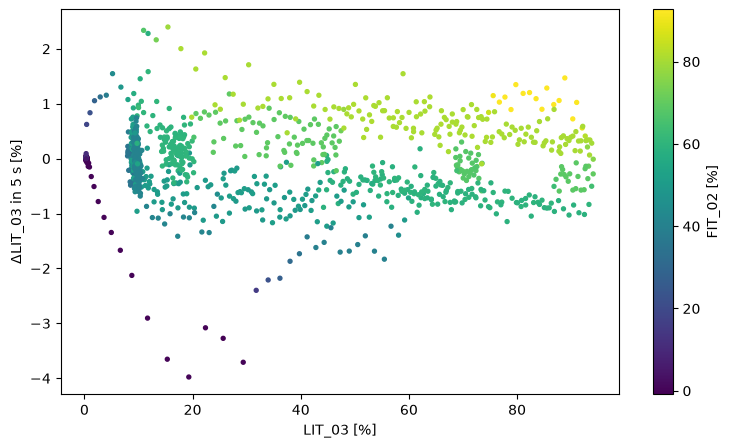

In [18]:
s = tables[3]
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(s["LIT_03"], s["dLIT_03"], c=s["FIT_02"], cmap="viridis", s=8)
fig.colorbar(sc, label="FIT_02 [%]")
ax.set_xlabel("LIT_03 [%]"); ax.set_ylabel("ΔLIT_03 in 5 s [%]")
plt.show()

In [19]:
BANDS = [0, 20, 40, 60, 80, 100]
for t, ins in TANKS.items():
    tb = tables[t]
    print(f"--- tank {t}: {ins[0]} vs {ins[-1]} (% of steps)")
    print(pd.crosstab(pd.cut(tb[ins[0]], BANDS, include_lowest=True),
                      pd.cut(tb[ins[-1]], BANDS, include_lowest=True),
                      normalize=True).mul(100).round(1))

--- tank 3: LIT_03 vs FIT_02 (% of steps)
FIT_02          (-0.001, 20.0]  (20.0, 40.0]  (40.0, 60.0]  (60.0, 80.0]  \
LIT_03                                                                     
(-0.001, 20.0]             9.7           1.8          36.9           3.5   
(20.0, 40.0]               0.3           0.3           5.0           3.9   
(40.0, 60.0]               0.0           0.9           6.8           2.5   
(60.0, 80.0]               0.0           0.0           6.4           3.0   
(80.0, 100.0]              0.0           0.0           2.0           2.3   

FIT_02          (80.0, 100.0]  
LIT_03                         
(-0.001, 20.0]            0.2  
(20.0, 40.0]              1.6  
(40.0, 60.0]              3.1  
(60.0, 80.0]              5.5  
(80.0, 100.0]             4.3  
--- tank 4: LIT_04 vs FIT_01 (% of steps)
FIT_01          (20.0, 40.0]  (40.0, 60.0]  (60.0, 80.0]  (80.0, 100.0]
LIT_04                                                                 
(-0.001, 20.0] 

In [23]:
for t, tb in tables.items():
    lvl = TANKS[t][0]
    piece = (tb["t_s"] // 600).astype(int)        # 10-minute pieces
    is_chk = piece % 4 == 3                       # every 4th piece -> checking
    trn, chk = tb[~is_chk], tb[is_chk]
    cov = pd.DataFrame({
        "train": pd.cut(trn[lvl], BANDS, include_lowest=True).value_counts(sort=False),
        "check": pd.cut(chk[lvl], BANDS, include_lowest=True).value_counts(sort=False)})
    print(f"--- tank {t}: {len(trn)} train, {len(chk)} check"); print(cov)

    trn.drop(columns="t_s").to_csv(OUT / f"B_train_tank{t}.csv", index=False)
    chk.drop(columns="t_s").to_csv(OUT / f"B_check_tank{t}.csv", index=False)

--- tank 3: 914 train, 238 check
                train  check
LIT_03                      
(-0.001, 20.0]    575     25
(20.0, 40.0]       84     45
(40.0, 60.0]       91     62
(60.0, 80.0]      123     48
(80.0, 100.0]      41     58
--- tank 4: 914 train, 238 check
                train  check
LIT_04                      
(-0.001, 20.0]    354    180
(20.0, 40.0]      102     34
(40.0, 60.0]      110     24
(60.0, 80.0]      220      0
(80.0, 100.0]     128      0
--- tank 1: 914 train, 238 check
                train  check
LIT_01                      
(-0.001, 20.0]    468    161
(20.0, 40.0]      236     28
(40.0, 60.0]       38     21
(60.0, 80.0]      172     28
(80.0, 100.0]       0      0
--- tank 2: 914 train, 238 check
                train  check
LIT_02                      
(-0.001, 20.0]    353    120
(20.0, 40.0]      223     25
(40.0, 60.0]      228     93
(60.0, 80.0]       98      0
(80.0, 100.0]      12      0
